# COU 07506 Digital Signal Processing — Week 04: z-Transform Laboratory, Poles, Zeros and Stability
Name: KILIAKI, LAURENT HASSANI 

Registration No.: 240647412039

Class: BEng24ETE-1 

Date: 26/11/2026

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display
plt.rcParams["figure.figsize"] = (9, 3.5)

Pre-lab (Markdown cell)

(a) H(z) = 1/(1 − 0.9z⁻¹ + 0.81z⁻²). The poles are the roots of z² − 0.9z + 0.81 = 0:

z = [0.9 ± √(0.81 − 3.24)] / 2 = 0.45 ± j0.779, which is 0.9 e^(±jπ/3).

|p| = 0.9 < 1, so the causal system is stable.

(b) X(z) = 1/[(1 − 0.5z⁻¹)(1 − 0.25z⁻¹)] = A/(1 − 0.5z⁻¹) + B/(1 − 0.25z⁻¹), with

A = 1/(1 − 0.25/0.5) = 2
B = 1/(1 − 0.5/0.25) = −1

So X(z) = 2/(1 − 0.5z⁻¹) − 1/(1 − 0.25z⁻¹), giving x(n) = 2(0.5)ⁿ − (0.25)ⁿ. Check: x(0) = 1.

**Task 4.1: A pole-zero plotting function**

In [3]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)            # unit circle
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal"); ax.legend()
    ax.set_xlabel("Re"); ax.set_ylabel("Im")
    return z, p

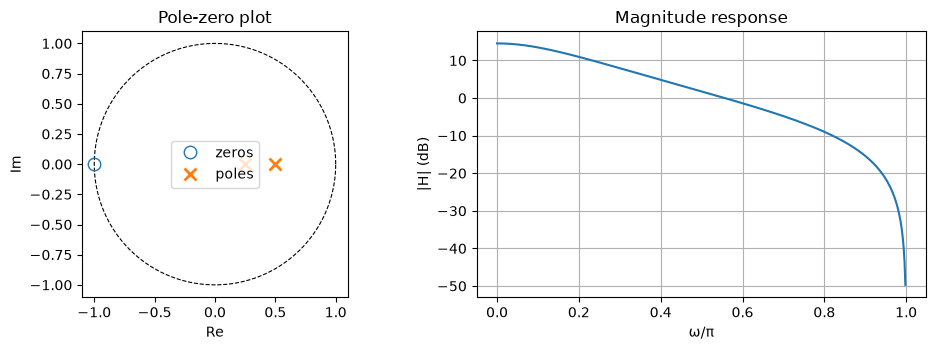

zeros: [-1.]  poles: [0.5  0.25]  stable: True


In [4]:
b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot")
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π"); ax2.set_ylabel("|H| (dB)")
ax2.set_title("Magnitude response"); ax2.grid(True)
plt.tight_layout(); plt.show()
print("zeros:", z, " poles:", p, " stable:", np.all(np.abs(p) < 1))